In [4]:
%pip install -U langgraph

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

In [6]:
class BatsmanState(TypedDict):
    runs: int
    balls: int
    fours: int
    sixes: int
    strike_rate: float
    balls_per_boundary: float
    boundary_percentage: float

In [8]:
def calculate_strike_rate(runs: int, balls: int) -> float:
    return (runs / balls) * 100 if balls > 0 else 0.0

In [14]:
# function for boundary percentage
def calculate_boundary_percentage(
    runs: int, fours: int, sixes: int
) -> float:
    boundary_runs = (4 * fours) + (6 * sixes)
    return (boundary_runs / runs) * 100 if runs > 0 else 0.0

In [10]:
def calculate_batsman_state(runs: int, balls: int, fours: int, sixes: int) -> BatsmanState:
    strike_rate = (runs / balls) * 100 if balls > 0 else 0.0
    total_boundaries = fours + sixes
    balls_per_boundary = (balls / total_boundaries) if total_boundaries > 0 else 0.0
    boundary_percentage = (total_boundaries / balls) * 100 if balls > 0 else 0.0

    return BatsmanState(
        runs=runs,
        balls=balls,
        fours=fours,
        sixes=sixes,
        strike_rate=strike_rate,
        balls_per_boundary=balls_per_boundary,
        boundary_percentage=boundary_percentage
    )

In [15]:
def summary(state: BatsmanState) -> str:
    return (
        f"Runs: {state['runs']}, Balls: {state['balls']}, "
        f"Fours: {state['fours']}, Sixes: {state['sixes']}, "
        f"Strike Rate: {state['strike_rate']:.2f}, "
        f"Balls per Boundary: {state['balls_per_boundary']:.2f}, "
        f"Boundary Percentage: {state['boundary_percentage']:.2f}%"
    )

In [18]:
from langgraph.graph import StateGraph, START, END

graph = StateGraph(BatsmanState)

In [19]:
from langgraph.graph import StateGraph, START, END

graph = StateGraph(BatsmanState)

In [20]:
#registering node
graph.add_node("Calculate Strike Rate", calculate_strike_rate)

In [21]:
# 3. Phir edge connect karo
graph.add_edge(START, "Calculate Strike Rate")


In [23]:
workflow = graph.compile()

In [24]:
print(workflow)


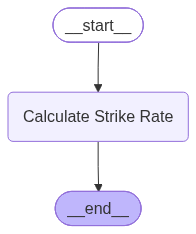

In [26]:
from IPython.display import display, Image

display(Image(workflow.get_graph().draw_mermaid_png()))


In [ ]:
def calculate_strike_rate(runs: int, balls: int) -> float:
    return (runs / balls) * 100 if balls > 0 else 0.0


In [ ]:
def calculate_strike_rate(state: BatsmanState) -> dict:
    runs = state["runs"]
    balls = state["balls"]

    return {
        "strike_rate": (runs / balls) * 100 if balls > 0 else 0.0
    }
    

In [34]:
graph = StateGraph(BatsmanState)

graph.add_node("Calculate Strike Rate", calculate_strike_rate)
graph.add_edge(START, "Calculate Strike Rate")
graph.add_edge("Calculate Strike Rate", END)

workflow = graph.compile()

In [35]:
initial_state = {
    "runs": 60,
    "balls": 30,
    "fours": 6,
    "sixes": 3
}

result = workflow.invoke(initial_state)
print(result)


{'runs': 60, 'balls': 30, 'fours': 6, 'sixes': 3, 'strike_rate': 200.0}


In [36]:
git init

SyntaxError: invalid syntax (2830201818.py, line 1)